# BT4012 – Fraudulent Bitcoin Transaction Detection
Pipeline: data loading -> graph features -> time steps -> model zoo (linear, bagging, boosting, residual MLP,
GNN) -> forward-in-time validation -> rank-average blend -> late-regime detection + self-training on the
test features -> submission.

Notes on protocol
* While the train files carry a `time_step` column, it is useful only to build **rolling forward-in-time validation**
  (train early, validate later) and for diagnostics.

In [36]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
N_JOBS = 4
os.environ["OMP_NUM_THREADS"] = str(N_JOBS)

import time, warnings, random
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components
from scipy.stats import rankdata, spearmanr
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

warnings.filterwarnings("ignore")

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier

## 1. Load data

In [37]:
train_full = pd.read_csv("train.csv")
train = train_full[train_full["label"].notna()].reset_index(drop=True)   # keep labelled rows only
test = pd.read_csv("test.csv")

edges = pd.read_csv("txs_edgelist.csv")

y = train["label"].astype(int).values
FEATS = [f"feat_{i}" for i in range(1, 166)]
print("train", train.shape, "| time steps", train.time_step.min(), "-", train.time_step.max(), "| illicit rate %.3f" % y.mean())
print("test ", test.shape, "| time steps", test.time_step.min(), "-", test.time_step.max())
print("edges", edges.shape)
print("NaNs  train/test:", int(train[FEATS].isna().sum().sum()), int(test[FEATS].isna().sum().sum()))

train (31235, 168) | time steps 1 - 35 | illicit rate 0.117
test  (15329, 168) | time steps 36 - 49
edges (234355, 2)
NaNs  train/test: 0 0


## 2. Graph construction and feature engineering

In [38]:
all_ids = np.unique(np.concatenate([edges.txId1.values, edges.txId2.values, train.txId.values, test.txId.values]))
id2pos = pd.Series(np.arange(len(all_ids)), index=all_ids)
src = id2pos[edges.txId1.values].values
dst = id2pos[edges.txId2.values].values
N = len(all_ids)
A = sp.coo_matrix((np.ones(len(src)), (src, dst)), shape=(N, N)).tocsr()   # directed
A_und = ((A + A.T) > 0).astype(np.float32).tocsr()                          # undirected

n_comp, comp = connected_components(A_und, directed=False)
comp_size = np.bincount(comp)
in_deg = np.asarray(A.sum(0)).ravel()
out_deg = np.asarray(A.sum(1)).ravel()
# 2-hop reach (undirected) as a cheap structural descriptor
two_hop = np.asarray((A_und @ A_und).sign().sum(1)).ravel()

graph_df = pd.DataFrame({
    "g_in_deg": in_deg, "g_out_deg": out_deg, "g_deg": in_deg + out_deg,
    "g_log_deg": np.log1p(in_deg + out_deg),
    "g_out_in_ratio": (out_deg + 1) / (in_deg + 1),
    "g_comp_size": comp_size[comp], "g_two_hop": two_hop,
}, index=all_ids)

def graph_features(df):
    """Per-node graph features aligned to df rows."""
    g = graph_df.loc[df.txId.values].reset_index(drop=True)
    return g

# Neighbour mean of a handful of raw features, restricted to neighbours whose features we hold.
NB_COLS = FEATS[:20]
feat_all = pd.concat([train[["txId"] + NB_COLS], test[["txId"] + NB_COLS]], ignore_index=True)
X_full = np.zeros((N, len(NB_COLS)), dtype=np.float32)
has_feat = np.zeros(N, dtype=np.float32)
pos = id2pos[feat_all.txId.values].values
X_full[pos] = feat_all[NB_COLS].values
has_feat[pos] = 1.0
nb_cnt = A_und @ has_feat
nb_mean = (A_und @ X_full) / np.maximum(nb_cnt, 1)[:, None]
nb_df = pd.DataFrame(nb_mean, columns=[f"nbmean_{c}" for c in NB_COLS], index=all_ids)
nb_df["nb_known_cnt"] = nb_cnt

def build_X(df):
    g = graph_features(df)
    nb = nb_df.loc[df.txId.values].reset_index(drop=True)
    X = pd.concat([df[FEATS].reset_index(drop=True), g, nb], axis=1)
    return X.replace([np.inf, -np.inf], np.nan).fillna(0.0)

X_tr_base, X_te_base = train[FEATS].reset_index(drop=True), test[FEATS].reset_index(drop=True)
X_tr, X_te = build_X(train), build_X(test)
groups = comp[id2pos[train.txId.values].values]
print("raw feats:", X_tr_base.shape[1], "| engineered total:", X_tr.shape[1])
print("components:", n_comp, "| train groups:", len(np.unique(groups)), "| largest comp:", comp_size.max())

raw feats: 165 | engineered total: 193
components: 49 | train groups: 35 | largest comp: 7880


## 3. Time steps for the train rows
While the train files contain a `time_step` column, it is useful only to build forward-in-time validation folds and for
diagnostics, but can't be used as a model input. Connected transactions share a time step, so each weakly-connected component of
the full edge list is one time step. Six "clock" features have a per-step median that is monotone in time on the test period, and
the train range of those features lies strictly below the test range, which is used in the drift diagnostics below.

In [39]:
t_tr = train["time_step"].astype(int).values
t_te = test.time_step.values

te_comp = comp[id2pos[test.txId.values].values]

# clock features: the per-step median of these moves monotonically with time on the test period
med_te = test.groupby("time_step")[FEATS].median()
rho = med_te.apply(lambda s: spearmanr(s.values, med_te.index.values)[0])
CLOCKS = rho[rho.abs() > 0.99].index.tolist()
sign = np.sign(rho[CLOCKS])
med_tr = train.groupby("time_step")[CLOCKS].median() * sign

print("clock features:", CLOCKS)
print("train steps: %d..%d | test steps %d..%d" % (t_tr.min(), t_tr.max(), t_te.min(), t_te.max()))
print("train clock medians stay below test:",
      bool((med_tr.max() < (med_te[CLOCKS] * sign).min()).all()))

clock features: ['feat_100', 'feat_101', 'feat_103', 'feat_136', 'feat_137', 'feat_139']
train steps: 1..35 | test steps 36..49
train clock medians stay below test: True


## 4. Diagnostics: how different are train and test?
Adversarial validation (can a model tell train rows from test rows?) and a per-step view of the label rate.

In [40]:
import torch, torch.nn as nn, torch.nn.functional as F
torch.set_num_threads(1)

Xa = pd.concat([X_tr, X_te], ignore_index=True); ya = np.r_[np.zeros(len(X_tr)), np.ones(len(X_te))]
pa = np.zeros(len(Xa)); gain = np.zeros(Xa.shape[1])
for a, b in StratifiedKFold(3, shuffle=True, random_state=0).split(Xa, ya):
    m = lgb.LGBMClassifier(n_estimators=150, learning_rate=0.05, colsample_bytree=0.5, importance_type="gain",
                           n_jobs=N_JOBS, verbose=-1, random_state=0).fit(Xa.iloc[a], ya[a])
    pa[b] = m.predict_proba(Xa.iloc[b])[:, 1]; gain += m.feature_importances_
print("adversarial AUC train-vs-test: %.3f  (1.0 = periods are fully distinguishable)" % roc_auc_score(ya, pa))
print("top drift features:", pd.Series(gain, index=Xa.columns).sort_values(ascending=False).head(8).index.tolist())
rate = pd.DataFrame({"t": t_tr, "y": y}).groupby("t").y.agg(["mean", "count"]).round(3)
print("illicit rate by train step (1-35):\n", rate.T.to_string())

adversarial AUC train-vs-test: 1.000  (1.0 = periods are fully distinguishable)
top drift features: ['feat_101', 'feat_103', 'feat_136', 'feat_100', 'feat_137', 'feat_139', 'feat_138', 'feat_106']
illicit rate by train step (1-35):
 t            1         2         3         4         5       6         7         8        9        10       11       12      13       14       15       16       17       18       19       20       21       22        23        24       25       26       27       28       29       30       31        32       33       34        35
mean      0.008     0.016     0.009     0.021     0.004    0.01     0.085     0.058    0.319    0.019    0.188    0.032    0.36    0.103    0.238    0.242    0.122    0.134    0.107    0.289    0.156     0.09     0.045     0.122    0.199    0.186    0.117    0.299     0.28    0.158    0.149     0.259    0.052    0.072     0.136
count  2147.000  1117.000  1279.000  1440.000  1882.000  485.00  1203.000  1165.000  778.000  972.000  696.

## 5. Model zoo
Class imbalance (~12% illicit in train) is handled with class weights. Tree models use the raw + graph features;
the neural networks use robust-scaled, clipped inputs.

In [41]:
POS_W = (y == 0).sum() / (y == 1).sum()

def make_models():
    return {
        "LogReg": lambda: LogisticRegression(C=0.1, class_weight="balanced", max_iter=2000, n_jobs=N_JOBS),
        "RandomForest": lambda: RandomForestClassifier(n_estimators=400, min_samples_leaf=2,
            class_weight="balanced_subsample", n_jobs=N_JOBS),
        "ExtraTrees": lambda: ExtraTreesClassifier(n_estimators=400, min_samples_leaf=2,
            class_weight="balanced_subsample", n_jobs=N_JOBS),
        "LightGBM": lambda: lgb.LGBMClassifier(n_estimators=600, learning_rate=0.03, num_leaves=31,
            subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=1.0, scale_pos_weight=POS_W,
            n_jobs=N_JOBS, verbose=-1),
        "XGBoost": lambda: xgb.XGBClassifier(n_estimators=600, learning_rate=0.03, max_depth=6,
            subsample=0.8, colsample_bytree=0.5, scale_pos_weight=POS_W, tree_method="hist", n_jobs=N_JOBS),
        "CatBoost": lambda: CatBoostClassifier(iterations=500, learning_rate=0.05, depth=6,
            auto_class_weights="Balanced", thread_count=N_JOBS, verbose=0),
    }
NEEDS_SCALING = {"LogReg"}

def fit_predict(name, factory, Xa, ya, Xb):
    if name in NEEDS_SCALING:
        sc = StandardScaler().fit(Xa); Xa, Xb = np.clip(sc.transform(Xa), -10, 10), np.clip(sc.transform(Xb), -10, 10)
    m = factory(); m.fit(Xa, ya)
    return m.predict_proba(Xb)[:, 1]

In [42]:
import threading, time

PROGRESS = {"msg": "starting", "done": 0, "total": 0, "t_update": time.time()}
def set_progress(msg=None, done=None, total=None):
    if msg is not None: PROGRESS["msg"] = msg
    if done is not None: PROGRESS["done"] = done
    if total is not None: PROGRESS["total"] = total
    PROGRESS["t_update"] = time.time()

class Heartbeat:
    def __init__(self, label, every=15, logfile="progress.log"):
        self.label, self.every, self.logfile = label, every, logfile
        self._stop = threading.Event()
    def _say(self, text):
        print(text, flush=True)
        with open(self.logfile, "a") as f: f.write(text + "\n")
    def _run(self):
        while not self._stop.wait(self.every):
            now, cpu = time.time(), time.process_time()
            util = 100 * (cpu - self._cpu0) / max(now - self._w0, 1e-9)
            self._cpu0, self._w0 = cpu, now
            P = dict(PROGRESS); idle = now - P["t_update"]
            pct = f"{P['done']}/{P['total']} ({100 * P['done'] / P['total']:.0f}%)" if P["total"] else "no step count"
            flag = "  <-- STALLED?" if idle > 30 and util < 5 else ""
            self._say(f"   [{self.label}] {now - self.t0:4.0f}s | {P['msg']} | {pct} | last report {idle:.0f}s ago | CPU {util:3.0f}%{flag}")
    def __enter__(self):
        self.t0 = self._w0 = time.time(); self._cpu0 = time.process_time()
        self._say(f"   [{self.label}] started; update every {self.every}s")
        threading.Thread(target=self._run, daemon=True).start(); return self
    def __exit__(self, *exc):
        self._stop.set(); self._say(f"   [{self.label}] finished after {time.time() - self.t0:.0f}s")

class Tick:
    def __init__(self, every=15): self.every, self.last = every, time.time()
    def due(self):
        now = time.time()
        if now - self.last >= self.every: self.last = now; return True
        return False

### 5b. Residual MLP (deep learning)
Residual blocks with BatchNorm + dropout, Gaussian-noise augmentation, AdamW + one-cycle schedule, softened
class weight and **short training** (8 epochs): longer training could overfit the training period. Predictions are averaged over several seeds.

In [43]:
class ResBlock(nn.Module):
    def __init__(self, d, p):
        super().__init__()
        self.net = nn.Sequential(nn.BatchNorm1d(d), nn.ReLU(), nn.Dropout(p), nn.Linear(d, d),
                                 nn.BatchNorm1d(d), nn.ReLU(), nn.Dropout(p), nn.Linear(d, d))
    def forward(self, x): return x + self.net(x)

class ResMLP(nn.Module):
    def __init__(self, d_in, d=256, n_blocks=3, p=0.3):
        super().__init__()
        self.inp = nn.Linear(d_in, d)
        self.blocks = nn.Sequential(*[ResBlock(d, p) for _ in range(n_blocks)])
        self.head = nn.Sequential(nn.BatchNorm1d(d), nn.ReLU(), nn.Linear(d, 1))
    def forward(self, x): return self.head(self.blocks(self.inp(x))).squeeze(-1)

def robust_scale(Xa, Xb):
    med = np.median(Xa, 0); q1, q3 = np.percentile(Xa, [25, 75], 0)
    sc = np.where(q3 - q1 > 1e-6, q3 - q1, Xa.std(0) + 1e-6)
    f = lambda X: np.clip((X - med) / sc, -6, 6).astype(np.float32)
    return f(Xa), f(Xb)

def resmlp_fit_predict(Xa, ya, Xb, seed=0, epochs=8, d=256, n_blocks=3, p=0.3, lr=2e-3, wd=1e-3, noise=0.05, bs=512, tag="ResMLP"):
    set_progress(f"{tag}: scaling data", 0, 0)
    torch.manual_seed(seed); np.random.seed(seed)
    A, B = robust_scale(Xa, Xb)
    set_progress(f"{tag}: building model")
    A, B, ya_t = torch.tensor(A), torch.tensor(B), torch.tensor(ya, dtype=torch.float32)
    m = ResMLP(A.shape[1], d, n_blocks, p)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=wd)
    n_batches = int(np.ceil(len(A) / bs)); total = epochs * n_batches
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=total)
    pw = torch.tensor(np.sqrt((ya == 0).sum() / max((ya == 1).sum(), 1)), dtype=torch.float32)
    step = 0
    for ep in range(epochs):
        m.train(); perm = torch.randperm(len(A))
        for i in range(0, len(A), bs):
            idx = perm[i:i + bs]
            if len(idx) < 8: continue
            set_progress(f"{tag}: epoch {ep + 1}/{epochs}, batch {i // bs + 1}/{n_batches}, forward", step, total)
            xb = A[idx] + noise * torch.randn(len(idx), A.shape[1])
            loss = F.binary_cross_entropy_with_logits(m(xb), ya_t[idx], pos_weight=pw)
            set_progress(f"{tag}: epoch {ep + 1}/{epochs}, batch {i // bs + 1}/{n_batches}, backward")
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            step += 1
    set_progress(f"{tag}: predicting", total, total)
    m.eval()
    with torch.no_grad(): return torch.sigmoid(m(B)).numpy()

N_SEEDS = 2
def resmlp_ensemble(Xa, ya, Xb):
    preds = []
    for s in range(N_SEEDS):
        print(f"   [ResMLP] seed {s + 1}/{N_SEEDS} (training on {len(ya):,} rows)", flush=True)
        preds.append(resmlp_fit_predict(Xa, ya, Xb, seed=s, epochs=8, tag=f"ResMLP seed {s + 1}"))
    return np.mean(preds, 0)

### 5c. Graph neural network (GraphSAGE, PyTorch Geometric)
Nodes = transactions we hold features for; edges = payment flows between two such transactions (induced
sub-graph; only ~16% of all edges qualify, which limits what message passing can add).

In [44]:
from torch_geometric.nn import SAGEConv
def induced_edge_index(ids):
    local = pd.Series(np.arange(len(ids)), index=ids)
    m = edges.txId1.isin(local.index) & edges.txId2.isin(local.index)
    a, b = local[edges.txId1[m].values].values, local[edges.txId2[m].values].values
    return torch.tensor(np.concatenate([np.stack([a, b]), np.stack([b, a])], axis=1), dtype=torch.long)

class SAGE(nn.Module):
    def __init__(self, d_in, d_h=128, dropout=0.3):
        super().__init__()
        self.c1, self.c2, self.out, self.dropout = SAGEConv(d_in, d_h), SAGEConv(d_h, d_h), nn.Linear(d_h, 1), dropout
    def forward(self, x, ei):
        x = F.dropout(F.relu(self.c1(x, ei)), self.dropout, self.training)
        x = F.dropout(F.relu(self.c2(x, ei)), self.dropout, self.training)
        return self.out(x).squeeze(-1)

def gnn_fit_predict(Xa, ya, ids_a, Xb, ids_b, epochs=150, lr=5e-3, tag="GraphSAGE"):
    t0, tick = time.time(), Tick(15)
    print(f"   [{tag}] start: {len(ya):,} nodes, {epochs} epochs (preparing graph...)", flush=True)
    A, B = robust_scale(Xa, Xb)
    xa, xb, ya_t = torch.tensor(A), torch.tensor(B), torch.tensor(ya, dtype=torch.float32)
    eia, eib = induced_edge_index(ids_a), induced_edge_index(ids_b)
    m = SAGE(xa.shape[1]); opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=1e-4)
    pw = torch.tensor((ya == 0).sum() / max((ya == 1).sum(), 1), dtype=torch.float32)
    t_train = time.time()
    for ep in range(epochs):
        m.train(); opt.zero_grad()
        loss = F.binary_cross_entropy_with_logits(m(xa, eia), ya_t, pos_weight=pw)
        loss.backward(); opt.step()
        if tick.due():
            done, el = ep + 1, time.time() - t_train
            print(f"   [{tag}] epoch {done}/{epochs} ({100 * done / epochs:.0f}%) | loss {loss.item():.4f} | "
                  f"{el:.0f}s training, ~{el / done * (epochs - done):.0f}s left", flush=True)
    m.eval()
    with torch.no_grad(): out = torch.sigmoid(m(xb, eib)).numpy()
    print(f"   [{tag}] done in {time.time() - t0:.0f}s", flush=True)
    return out

## 6. Rolling forward-in-time validation
Three folds: train on steps 1-17 -> validate 18-24; 1-24 -> 25-30; 1-30 -> 31-35. Then fit on all of train and
score the test period (steps 36-49).

In [45]:
FOLDS = [(17, range(18, 25)), (24, range(25, 31)), (30, range(31, 36))]
tr_ids, te_ids = train.txId.values, test.txId.values
fold_pred, test_pred, rows = {}, {}, []

def run(name, fit_fn):
    """fit_fn(train_idx, X_eval_matrix, eval_ids) is replaced by closures below; records fold scores and test scores."""
    set_progress(f"fitting {name}", 0, 0)
    t0 = time.time(); fp = []
    for fold_no, (cut, vr) in enumerate(FOLDS, 1):
        set_progress(f"{name}: fold {fold_no}/{len(FOLDS)}")
        tr_m, va_m = t_tr <= cut, np.isin(t_tr, list(vr))
        fp.append((np.where(va_m)[0], fit_fn(np.where(tr_m)[0], X_tr.values[va_m], tr_ids[va_m])))
    set_progress(f"{name}: final fit on all of train")
    tp = fit_fn(np.arange(len(y)), X_te.values, te_ids)
    fold_pred[name], test_pred[name] = fp, tp
    fa = [roc_auc_score(y[i], p) for i, p in fp]
    rows.append(dict(model=name, fwd_cv_auc=np.mean(fa), fwd_cv_std=np.std(fa),
                     seconds=round(time.time() - t0)))
    print(f"{name:16s} fwd-CV {np.mean(fa):.4f}±{np.std(fa):.4f} | {time.time()-t0:.0f}s", flush=True)

with Heartbeat("section 6"):
    for name, factory in make_models().items():
        run(name, lambda a, Xb, ids, n=name, f=factory: fit_predict(n, f, X_tr.values[a], y[a], Xb))
    run("ResMLP", lambda a, Xb, ids: resmlp_ensemble(X_tr.values[a], y[a], Xb))
    run("GNN_SAGE", lambda a, Xb, ids: gnn_fit_predict(X_tr.values[a], y[a], tr_ids[a], Xb, ids))

   [section 6] started; update every 15s
LogReg           fwd-CV 0.9125±0.0067 | 1s
   [section 6]   15s | RandomForest: fold 3/3 | no step count | last report 0s ago | CPU 353%
   [section 6]   30s | RandomForest: final fit on all of train | no step count | last report 5s ago | CPU 390%
RandomForest     fwd-CV 0.9694±0.0387 | 36s
   [section 6]   45s | ExtraTrees: final fit on all of train | no step count | last report 1s ago | CPU 355%
ExtraTrees       fwd-CV 0.9699±0.0366 | 11s
   [section 6]   60s | LightGBM: fold 3/3 | no step count | last report 4s ago | CPU 288%
LightGBM         fwd-CV 0.9772±0.0293 | 18s
   [section 6]   75s | XGBoost: fold 3/3 | no step count | last report 0s ago | CPU 274%
XGBoost          fwd-CV 0.9790±0.0261 | 18s
   [section 6]   90s | CatBoost: fold 1/3 | no step count | last report 6s ago | CPU 338%
   [section 6]  105s | CatBoost: fold 3/3 | no step count | last report 4s ago | CPU 393%
   [section 6]  120s | CatBoost: final fit on all of train | no ste

## 7. Ensembles (rank-average)
A neural network makes different errors from tree models, so adding it to the boosters helps even though it is
weaker alone.

In [46]:
def rank01(v): return rankdata(v) / len(v)
def blend_scores(members):
    fp = [(fold_pred[members[0]][i][0], np.mean([rank01(fold_pred[m][i][1]) for m in members], 0)) for i in range(len(FOLDS))]
    tp = np.mean([rank01(test_pred[m]) for m in members], 0)
    return fp, tp

BLENDS = {
    "Blend_ResMLP+LGB+XGB+Cat+ET+GNN": ["ResMLP", "LightGBM", "XGBoost", "CatBoost", "ExtraTrees", "GNN_SAGE"]
}
for bname, members in BLENDS.items():
    fp, tp = blend_scores(members); fold_pred[bname], test_pred[bname] = fp, tp
    fa = [roc_auc_score(y[i], p) for i, p in fp]
    rows.append(dict(model=bname, fwd_cv_auc=np.mean(fa), fwd_cv_std=np.std(fa), seconds=0))
    print(f"{bname:28s} fwd-CV {np.mean(fa):.4f} | {members}")

Blend_ResMLP+LGB+XGB+Cat+ET+GNN fwd-CV 0.9786 | ['ResMLP', 'LightGBM', 'XGBoost', 'CatBoost', 'ExtraTrees', 'GNN_SAGE']


## 8. Model comparison and blend choice
Models are compared on forward-in-time validation (mean AUC over the three folds). The base blend is fixed by design,
not picked by a score: it rank-averages every model family (neural, boosting, bagging, graph), because families make
different errors. On the public leaderboard it scored 0.95593 against 0.95029 for the earlier tree-only blend.
The forward-validation differences between the top blends are within noise.

In [47]:
results = pd.DataFrame(rows).set_index("model").sort_values("fwd_cv_auc", ascending=False)
pd.set_option("display.width", 200); print(results.round(4))
BLEND_NAME = "Blend_ResMLP+LGB+XGB+Cat+ET+GNN"; print("\nBase blend (fixed by design):", BLEND_NAME)
base_scores = test_pred[BLEND_NAME]                                            # rank-average score per test row

                                 fwd_cv_auc  fwd_cv_std  seconds
model                                                           
XGBoost                              0.9790      0.0261       18
Blend_ResMLP+LGB+XGB+Cat+ET+GNN      0.9786      0.0274        0
LightGBM                             0.9772      0.0293       18
CatBoost                             0.9766      0.0288       37
ResMLP                               0.9727      0.0234       42
ExtraTrees                           0.9699      0.0366       11
RandomForest                         0.9694      0.0387       36
GNN_SAGE                             0.9608      0.0309       72
LogReg                               0.9125      0.0067        1

Base blend (fixed by design): Blend_ResMLP+LGB+XGB+Cat+ET+GNN


In [48]:
def write_submission(scores, path):
    sub = pd.DataFrame({"index": test["index"].values, "target": scores}).sort_values("index")
    assert len(sub) == len(test) and sub["target"].between(0, 1).all()
    sub.to_csv(path, index=False)

## 9. Late-regime detection and self-training on the unlabelled test features
**Why.** The blend is strong on test steps 36-42 but weak on later steps: the late illicit rows look different from
anything in train (the model gives them mid-range scores, ~0.77 vs ~0.98 for earlier illicit rows).

**Detecting the regime change (no labels needed).** For each test step we compute the *alarm rate*: the share of rows
whose blend score is in the global top 5%. A step is flagged as a regime break when its alarm rate is below 25% of the
median alarm rate of the preceding steps (at least 3 steps seen); every step from the first break onwards is "late".
(The 25% threshold was chosen by us after inspecting the alarm-rate profile.)

**Self-training.** Within each late step, rows are ranked by the blend score. The top `Q_POS`% become pseudo-positives
and the bottom `Q_NEG`% pseudo-negatives (the middle is ignored). Models trained on the real training data plus these
pseudo-labelled late rows re-score the late rows. Cross-fitting (two random halves of the late rows, each scored by a
model trained on pseudo-labels from the *other* half) stops any row being scored by a model that saw its own label.

**Novelty nudge.** The blend's within-step rank is mixed with a small weight (`NOVELTY_W`=0.15; chosen from a handful of settings) of a label-free novelty
rank (mean distance to the 10 nearest licit training rows in a 30-component PCA space) before the top/bottom cut, so rows
that look unlike anything known are slightly more likely to be pseudo-positive. On its own the novelty rank is a weak
detector; it is used only to reshuffle borderline rows.

**Keeping scores comparable.** The new late ordering is mapped back onto the blend's own late score values, so only
the order within the late block changes; early steps are untouched and the pooled AUC stays well-defined.

**Fixed settings:** `Q_POS`=20% / `Q_NEG`=72% (the middle of a flat region of the settings we tried), the two views
and learners above, and `NOVELTY_W`=0.15. Things that did **not** help: a second self-training round, self-training the early steps, more
seeds or bigger learner ensembles on the full-feature view alone.

In [49]:
# --- 9a. detection of the late regime ---
thr = np.quantile(base_scores, 0.95)
alarm = pd.Series({s_: float((base_scores[t_te == s_] > thr).mean()) for s_ in sorted(np.unique(t_te))})
break_step = None
for k in range(3, len(alarm)):
    if alarm.iloc[k] < 0.25 * alarm.iloc[:k].median():
        break_step = int(alarm.index[k]); break
print("alarm rate by test step:", alarm.round(3).to_dict())
print("detected regime break at step:", break_step)

alarm rate by test step: {36: 0.026, 37: 0.062, 38: 0.144, 39: 0.074, 40: 0.073, 41: 0.104, 42: 0.1, 43: 0.007, 44: 0.02, 45: 0.009, 46: 0.01, 47: 0.004, 48: 0.006, 49: 0.017}
detected regime break at step: 43


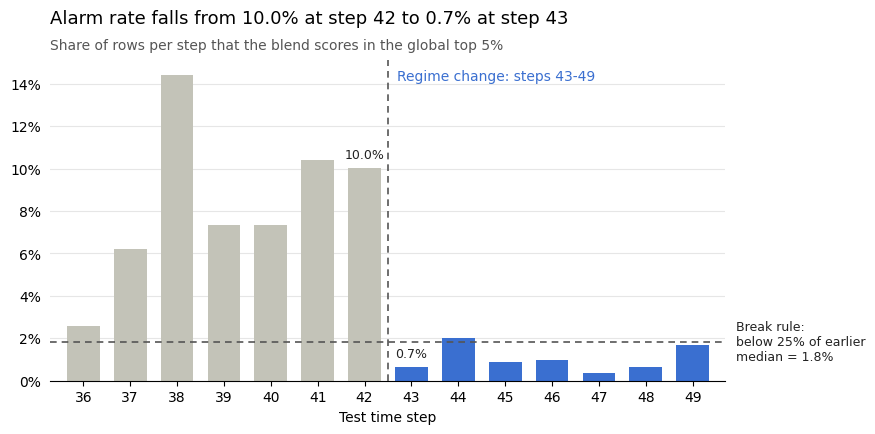

In [50]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# --- uses `alarm` (Series: step -> alarm rate) and `break_step` from section 9a ---
steps = alarm.index.astype(int).values
rates = alarm.values
early_median = alarm[alarm.index < break_step].median()      # median of the steps before the break
cutoff = 0.25 * early_median                                  # the break rule threshold

GREY, BLUE, INK = "#c3c3b8", "#3a6fd0", "#222222"
colors = [GREY if s < break_step else BLUE for s in steps]

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.bar(steps, rates, color=colors, width=0.7, zorder=2)

# horizontal dotted line: the break rule (25% of the earlier median)
ax.axhline(cutoff, color="#555555", ls=(0, (4, 3)), lw=1.2, zorder=3)
ax.set_xlim(steps.min() - 0.7, steps.max() + 0.7)
ax.text(1.015, cutoff, f"Break rule:\nbelow 25% of earlier\nmedian = {cutoff:.1%}",
        va="center", ha="left", fontsize=9, color=INK, clip_on=False, transform=ax.get_yaxis_transform())

# vertical dotted line: regime change
ax.axvline(break_step - 0.5, color="#555555", ls=(0, (4, 3)), lw=1.2, zorder=3)
ax.text(break_step - 0.3, ax.get_ylim()[1] * 0.97, f"Regime change: steps {break_step}-{steps.max()}",
        color=BLUE, fontsize=10, va="top", ha="left")

# label the last step before and the first step after the break
for s in (break_step - 1, break_step):
    r = alarm[s]
    ax.text(s, r + 0.003, f"{r:.1%}", ha="center", va="bottom", fontsize=9, color=INK)

ax.set_xticks(steps)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Test time step")
ax.set_title(f"Alarm rate falls from {alarm[break_step-1]:.1%} at step {break_step-1} to {alarm[break_step]:.1%} at step {break_step}",
             loc="left", fontsize=13, pad=26)
ax.text(0, 1.03, "Share of rows per step that the blend scores in the global top 5%", transform=ax.transAxes, fontsize=10, color="#555555")
ax.grid(axis="y", color="#e6e6e6", zorder=0)
for sp in ("top", "right", "left"): ax.spines[sp].set_visible(False)
ax.tick_params(left=False)
fig.subplots_adjust(right=0.80, top=0.84)
plt.savefig("alarm_rate.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
Q_POS, Q_NEG = 20, 72
NOVELTY_W = 0.15
SEEDS_LGB, SEEDS_XGB = tuple(range(10)), (0, 1, 2)

# Second view: drop the first half of the raw columns (feat_1..feat_82), keep everything after them
# (feat_83..feat_165 plus the 28 graph-derived columns). The first view uses all columns.
HALF = len(FEATS) // 2                                # = 82
assert X_tr.columns[164] == "feat_165" and X_tr.columns[165] == "g_in_deg"   # raw columns first, then graph-derived
HALF_VIEW = list(range(HALF, X_tr.shape[1]))
ALL_VIEW = list(range(X_tr.shape[1]))

def make_learner(kind, seed):
    if kind == "lgb":
        return lgb.LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=31, subsample=0.8,
            subsample_freq=1, colsample_bytree=0.5, scale_pos_weight=POS_W, n_jobs=N_JOBS, random_state=seed, verbose=-1)
    return xgb.XGBClassifier(n_estimators=400, learning_rate=0.04, max_depth=6, subsample=0.8,
        colsample_bytree=0.5, scale_pos_weight=POS_W, tree_method="hist", n_jobs=N_JOBS, random_state=seed)

final_scores = base_scores.copy()          # FINAL: first half of columns removed + novelty nudge
backup_scores = base_scores.copy()         # BACKUP: first half of columns removed, no novelty nudge

if break_step is not None:
    late = t_te >= break_step; li = np.where(late)[0]; tl = t_te[li]
    wr_base = np.zeros(len(li))                               # within-step rank of the blend score (late rows only)
    for s_ in np.unique(tl):
        k_ = tl == s_; wr_base[k_] = rankdata(base_scores[li][k_]) / k_.sum()
    Xtr_v, Xte_late = X_tr.values, X_te.values[li]

    # --- 9b0. label-free novelty score (computed once, used by the final stage only) ---
    _sc = StandardScaler().fit(Xtr_v)
    _Ztr, _Zl = np.clip(_sc.transform(Xtr_v), -6, 6), np.clip(_sc.transform(Xte_late), -6, 6)
    _pca = PCA(30, random_state=0).fit(_Ztr)
    _dist = NearestNeighbors(n_neighbors=10, n_jobs=N_JOBS).fit(_pca.transform(_Ztr[y == 0])).kneighbors(_pca.transform(_Zl))[0].mean(1)
    novelty = np.zeros(len(li))
    for s_ in np.unique(tl):
        k_ = tl == s_; novelty[k_] = rankdata(_dist[k_]) / k_.sum()

    def pseudo_label_rank(novelty_w):
        """Within-step rank of the blend, optionally nudged by the novelty rank, then re-ranked."""
        mix = wr_base + novelty_w * novelty; out = np.zeros(len(li))
        for s_ in np.unique(tl):
            k_ = tl == s_; out[k_] = rankdata(mix[k_]) / k_.sum()
        return out

    # --- 9b. cross-fitted self-training; returns the mean rank score over seeds for the late rows ---
    def self_train(kind, view, seeds, wr):
        outs = []
        for sd in seeds:
            fold = np.random.RandomState(sd).randint(0, 2, len(li)); new = np.zeros(len(li))
            for f in (0, 1):
                src = fold != f                               # pseudo-labels come from the other half
                pos_ = src & (wr >= 1 - Q_POS / 100); neg_ = src & (wr <= Q_NEG / 100); sel = pos_ | neg_
                m = make_learner(kind, sd).fit(np.r_[Xtr_v[:, view], Xte_late[sel][:, view]], np.r_[y, pos_[sel].astype(int)])
                new[fold == f] = m.predict_proba(Xte_late[fold == f][:, view])[:, 1]
            outs.append(rankdata(new) / len(new))
        return np.mean(outs, 0)

    rk = lambda v: rankdata(v) / len(v)
    def late_model(novelty_w, tag):
        wr = pseudo_label_rank(novelty_w)
        parts = {"half_lgb": self_train("lgb", HALF_VIEW, SEEDS_LGB, wr), "half_xgb": self_train("xgb", HALF_VIEW, SEEDS_XGB, wr),
                 "full_lgb": self_train("lgb", ALL_VIEW, SEEDS_LGB, wr), "full_xgb": self_train("xgb", ALL_VIEW, SEEDS_XGB, wr)}
        new_rank = np.mean([rk(v) for v in parts.values()], 0)
        # --- 9c. map the new late ordering onto the blend's own late score values ---
        order_idx = np.minimum(rankdata(new_rank).astype(int), len(li)) - 1
        scores = base_scores.copy(); scores[li] = np.sort(base_scores[li])[order_idx]
        print(f"[{tag}] late rows re-scored: {len(li)} of {len(t_te)}", flush=True)
        return scores, parts, new_rank, wr

    backup_scores, _, _, _ = late_model(0.0, "BACKUP: first half of columns removed")
    final_scores, parts, new_rank, wr = late_model(NOVELTY_W, "FINAL: first half removed + novelty nudge")

for nm, sc in [("final", final_scores), ("backup", backup_scores)]:
    print(f"{nm}: rank correlation with base blend on all rows: {np.corrcoef(rankdata(sc), rankdata(base_scores))[0, 1]:.4f}")

## 10. Final comparison table and submission

In [ ]:
rows.append(dict(model=f"{BLEND_NAME}+SelfTrain2View(half-cols removed,q+={Q_POS}%,q-={Q_NEG}%) [backup]", fwd_cv_auc=np.nan, fwd_cv_std=np.nan, seconds=0))
rows.append(dict(model=f"{BLEND_NAME}+SelfTrain2View(half-cols removed,q+={Q_POS}%,q-={Q_NEG}%,novelty={NOVELTY_W}) [final]", fwd_cv_auc=np.nan, fwd_cv_std=np.nan, seconds=0))
results = pd.DataFrame(rows).set_index("model").sort_values("fwd_cv_auc", ascending=False)
print(results.round(4))

write_submission(final_scores,  "final_submission.csv")    # FINAL: first half of columns removed + novelty nudge
write_submission(backup_scores, "backup_submission.csv")   # BACKUP: first half of columns removed, no novelty nudge
print("saved", os.path.abspath("final_submission.csv"), "and", os.path.abspath("backup_submission.csv"))